# Lab 3 - Supervised vs Unsupervised Anomaly Detection

Notebook structure follows the assignment tasks. Training runs are numbered as in `LOGBOOK.md`; answers are in `NOTES.md`.

In [12]:
import random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
random.seed(SEED); np.random.seed(SEED)
pd.set_option('display.max_columns', 60)

TRAIN_PATH, TEST_PATH = 'Lab3_train.csv', 'Lab3_test.csv'
train_raw = pd.read_csv(TRAIN_PATH)
test_raw  = pd.read_csv(TEST_PATH)
print('train', train_raw.shape, '| test', test_raw.shape)

train (18831, 43) | test (5826, 43)


## Task 1 - The data from a domain-expert perspective

### Task 1.1 - Explore the dataset

In [13]:
LABEL, BIN = 'label', 'binary_label'
FEATURES = [c for c in train_raw.columns if c not in (LABEL, BIN)]
CAT_COLS = [c for c in FEATURES if not pd.api.types.is_numeric_dtype(train_raw[c])]
NUM_COLS = [c for c in FEATURES if c not in CAT_COLS]
BIN01_COLS = [c for c in NUM_COLS if set(train_raw[c].unique()) <= {0, 1}]
print(f'{len(FEATURES)} features: {len(CAT_COLS)} categorical, {len(NUM_COLS)} numerical (0/1 counted as numerical)')
print('Categorical:', CAT_COLS)
print('0/1 numerical:', BIN01_COLS)
for c in CAT_COLS:
    unseen = sorted(set(test_raw[c]) - set(train_raw[c]))
    print(f'{c}: {train_raw[c].nunique()} levels in train, {test_raw[c].nunique()} in test; unseen in test: {unseen}')

41 features: 3 categorical, 38 numerical (0/1 counted as numerical)
Categorical: ['protocol_type', 'service', 'flag']
0/1 numerical: ['land', 'urgent', 'logged_in', 'root_shell', 'num_shells', 'num_outbound_cmds', 'is_host_login', 'is_guest_login']
protocol_type: 3 levels in train, 3 in test; unseen in test: []
service: 65 levels in train, 61 in test; unseen in test: ['tftp_u', 'tim_i']
flag: 11 levels in train, 11 in test; unseen in test: []


In [14]:
def label_table(df):
    t = pd.DataFrame({'count': df[LABEL].value_counts(), '%': (df[LABEL].value_counts(normalize=True)*100).round(2)})
    return t

dist = pd.concat({'train': label_table(train_raw), 'test': label_table(test_raw)}, axis=1).fillna(0)
display(dist)
for name, df in [('train', train_raw), ('test', test_raw)]:
    n_anom = df[BIN].sum()
    print(f'{name}: normal={len(df)-n_anom}, anomalous={n_anom}, anomaly fraction={n_anom/len(df):.4f}')
    # consistency between attack label and binary label
    assert ((df[LABEL] != 'normal').astype(int) == df[BIN]).all()

train           test       
        count      %   count      %
label                              
normal  13448  71.41  2152.0  36.94
dos      2913  15.47  2577.0  44.23
probe    2289  12.16  1097.0  18.83
r2l       181   0.96     0.0   0.00

train: normal=13448, anomalous=5383, anomaly fraction=0.2859
test: normal=2152, anomalous=3674, anomaly fraction=0.6306


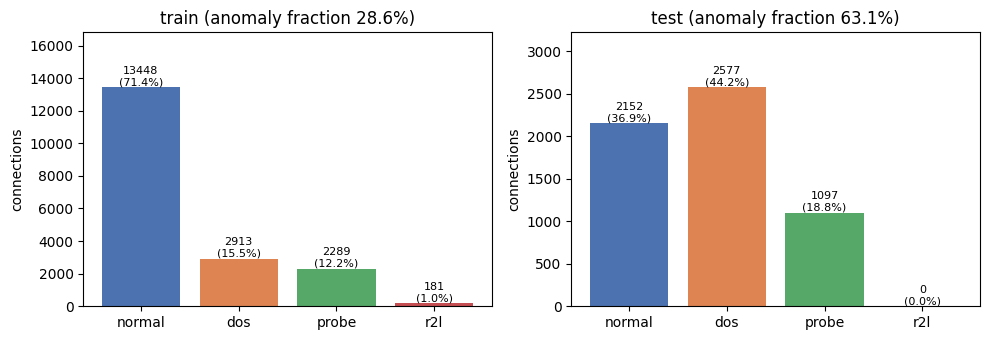

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
order = ['normal', 'dos', 'probe', 'r2l']
for ax, (name, df) in zip(axes, [('train', train_raw), ('test', test_raw)]):
    vc = df[LABEL].value_counts().reindex(order, fill_value=0)
    ax.bar(vc.index, vc.values, color=['#4C72B0', '#DD8452', '#55A868', '#C44E52'])
    for i, v in enumerate(vc.values):
        ax.text(i, v, f'{v}\n({v/len(df):.1%})', ha='center', va='bottom', fontsize=8)
    ax.set_title(f'{name} (anomaly fraction {df[BIN].mean():.1%})'); ax.set_ylabel('connections')
    ax.set_ylim(0, vc.max()*1.25)
plt.tight_layout(); plt.show()

In [16]:
# Data quality checks (no rows are modified here)
for name, df in [('train', train_raw), ('test', test_raw)]:
    num = df[NUM_COLS]
    print(f'{name}: missing={df.isna().sum().sum()}, inf={np.isinf(num).sum().sum()}, '
          f'negative={(num < 0).sum().sum()}, duplicate rows={df.duplicated().sum()}, '
          f'duplicate feature vectors={df[FEATURES].duplicated().sum()}')
    print('   constant numerical columns:', [c for c in NUM_COLS if df[c].nunique() == 1])
conf = train_raw[train_raw.duplicated(FEATURES, keep=False)]
print('\nFeature vectors with conflicting labels in train:'); display(conf[['protocol_type','service','flag','src_bytes',LABEL]])
overlap = test_raw.merge(train_raw, how='inner', on=list(train_raw.columns))
print('Test rows identical to a training row:', len(overlap))

train: missing=0, inf=0, negative=0, duplicate rows=0, duplicate feature vectors=1
   constant numerical columns: ['urgent', 'num_outbound_cmds', 'is_host_login']
test: missing=0, inf=0, negative=0, duplicate rows=0, duplicate feature vectors=0
   constant numerical columns: ['land', 'urgent', 'num_shells', 'num_outbound_cmds', 'is_host_login']

Feature vectors with conflicting labels in train:


,protocol_type,service,flag,src_bytes,label
8087,icmp,ecr_i,SF,20,probe
8800,icmp,ecr_i,SF,20,normal


Test rows identical to a training row: 75


In [17]:
print('Protocol by label (train):'); display(pd.crosstab(train_raw[LABEL], train_raw['protocol_type']))
print('Heavy-tailed numerical features (train):')
display(train_raw[NUM_COLS].describe().T.query('max > 1')[['mean','50%','max']].sort_values('max', ascending=False))

Protocol by label (train):


protocol_type,icmp,tcp,udp
label,,,
dos,529,2196,188
normal,261,10680,2507
probe,827,1147,315
r2l,0,181,0


Heavy-tailed numerical features (train):


,mean,50%,max
src_bytes,32545.325155,207.0,381709090.0
dst_bytes,3238.092719,136.0,5131424.0
duration,407.959057,0.0,42862.0
num_root,0.330253,0.0,975.0
num_compromised,0.301630,0.0,884.0
count,55.027508,6.0,511.0
srv_count,33.330891,6.0,511.0
dst_host_count,161.085126,222.0,255.0
dst_host_srv_count,149.129149,188.0,255.0
hot,0.261324,0.0,77.0


### Task 1.2 - Preprocessing

Decisions (justified in NOTES):
1. Drop numerical columns that are constant in **train** (no information, they would only add zero-variance dimensions).
2. Categorical: one-hot encoding fitted on train. `service` levels with < 10 training rows are merged into one *infrequent* column; categories unseen in train (`tftp_u`, `tim_i` in test) also map to it instead of producing an all-zero vector.
3. Numerical: `log1p` on non-rate counters/byte counts with training skewness > 2 (rule decided on train only), then `MinMaxScaler` on all numerical columns, so every feature (rates, 0/1 indicators, one-hot, counters) lives on a comparable [0, 1] scale. We first tried `StandardScaler`: it inflates sparse indicators (e.g. `land`, 1 in ~18.8k rows, reaches 137 standard deviations), so a single rare flag would dominate Euclidean/RBF distances. The comparison is kept below.
4. Every parameter (constant columns, skewness, category levels, min/max) is estimated on **train.csv only** and then applied unchanged to test.

In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler, FunctionTransformer

CONST_COLS = [c for c in NUM_COLS if train_raw[c].nunique() == 1]
NUM_KEEP = [c for c in NUM_COLS if c not in CONST_COLS]
RATE_COLS = [c for c in NUM_KEEP if c.endswith('_rate')]
skew = train_raw[NUM_KEEP].skew()
LOG_COLS = [c for c in NUM_KEEP if c not in RATE_COLS and c not in BIN01_COLS and skew[c] > 2]
LIN_COLS = [c for c in NUM_KEEP if c not in LOG_COLS]
print('Dropped constant:', CONST_COLS)
print(f'log1p + min-max ({len(LOG_COLS)}):', LOG_COLS)
print(f'min-max only ({len(LIN_COLS)}):', LIN_COLS)
display(skew[LOG_COLS + ['count', 'srv_count', 'dst_host_count', 'dst_host_srv_count']].drop_duplicates().round(2).to_frame('train skew'))

Dropped constant: ['urgent', 'num_outbound_cmds', 'is_host_login']
log1p + min-max (13): ['duration', 'src_bytes', 'dst_bytes', 'wrong_fragment', 'hot', 'num_failed_logins', 'num_compromised', 'su_attempted', 'num_root', 'num_file_creations', 'num_access_files', 'count', 'srv_count']
min-max only (22): ['land', 'logged_in', 'root_shell', 'num_shells', 'is_guest_login', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate']


,train skew
duration,9.94
src_bytes,136.22
dst_bytes,73.62
wrong_fragment,9.88
hot,11.78
num_failed_logins,58.46
num_compromised,53.81
su_attempted,33.03
num_root,53.95
num_file_creations,47.51


In [19]:
def make_preprocessor(scaler_cls):
    return ColumnTransformer([
        ('log_num', Pipeline([('log1p', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                              ('scale', scaler_cls())]), LOG_COLS),
        ('num', scaler_cls(), LIN_COLS),
        ('cat', OneHotEncoder(min_frequency=10, handle_unknown='infrequent_if_exist', sparse_output=False), CAT_COLS),
    ], remainder='drop', verbose_feature_names_out=True)

# Rejected alternative: StandardScaler. Inspect how far sparse features are pushed.
_std = make_preprocessor(StandardScaler).fit(train_raw[FEATURES])
_Xs = _std.transform(train_raw[FEATURES])
_names = _std.get_feature_names_out()
print('StandardScaler: largest training values (std units) ->')
display(pd.Series(_Xs.max(0), index=_names).sort_values(ascending=False).head(6).round(1).to_frame('max'))

preprocessor = make_preprocessor(MinMaxScaler)

# Fit on the full training file only (labels are NOT passed); apply unchanged to test.
X_train = preprocessor.fit_transform(train_raw[FEATURES])
X_test  = preprocessor.transform(test_raw[FEATURES])
FEATURE_NAMES = preprocessor.get_feature_names_out()
y_train_bin, y_test_bin = train_raw[BIN].to_numpy(), test_raw[BIN].to_numpy()
y_train_lab, y_test_lab = train_raw[LABEL].to_numpy(), test_raw[LABEL].to_numpy()

n_cat = sum(n.startswith('cat__') for n in FEATURE_NAMES)
print('X_train', X_train.shape, '| X_test', X_test.shape, f'| {X_train.shape[1]-n_cat} numerical + {n_cat} one-hot')
print('one-hot per column:', {c: sum(n.startswith(f'cat__{c}_') for n in FEATURE_NAMES) for c in CAT_COLS})
print('infrequent service levels:', preprocessor.named_transformers_['cat'].infrequent_categories_[1])
for name, raw in [('test', test_raw)]:
    unseen = raw['service'].isin(['tftp_u', 'tim_i']).to_numpy()
    print('unseen test rows -> infrequent column:', X_test[unseen][:, list(FEATURE_NAMES).index('cat__service_infrequent_sklearn')])
assert np.isfinite(X_train).all() and np.isfinite(X_test).all()

StandardScaler: largest training values (std units) ->


,max
num__land,137.2
log_num__num_failed_logins,65.8
num__num_shells,48.5
log_num__num_access_files,40.3
log_num__num_file_creations,40.1
log_num__num_compromised,34.5


X_train (18831, 106) | X_test (5826, 106) | 35 numerical + 71 one-hot
one-hot per column: {'protocol_type': 3, 'service': 57, 'flag': 11}
infrequent service levels: ['http_8001' 'pm_dump' 'pop_2' 'printer' 'red_i' 'remote_job' 'rje'
 'shell' 'urh_i']
unseen test rows -> infrequent column: [1. 1.]


MinMax: train range is [0, 1] by construction; test values outside [0, 1]: 7


,train mean,test mean,test min,test max
log_num__duration,0.042,0.010,0.000,1.022
log_num__hot,0.011,0.018,0.000,1.062
log_num__num_file_creations,0.001,0.000,0.000,1.243
log_num__count,0.309,0.596,-0.125,1.000
log_num__srv_count,0.270,0.362,-0.125,1.000


Largest train->test mean shifts (larger dos share in test):


num__logged_in                 0.400
log_num__count                 0.287
num__dst_host_count            0.269
num__same_srv_rate             0.241
num__dst_host_same_srv_rate    0.199
num__dst_host_rerror_rate      0.192
Name: shift, dtype: float64

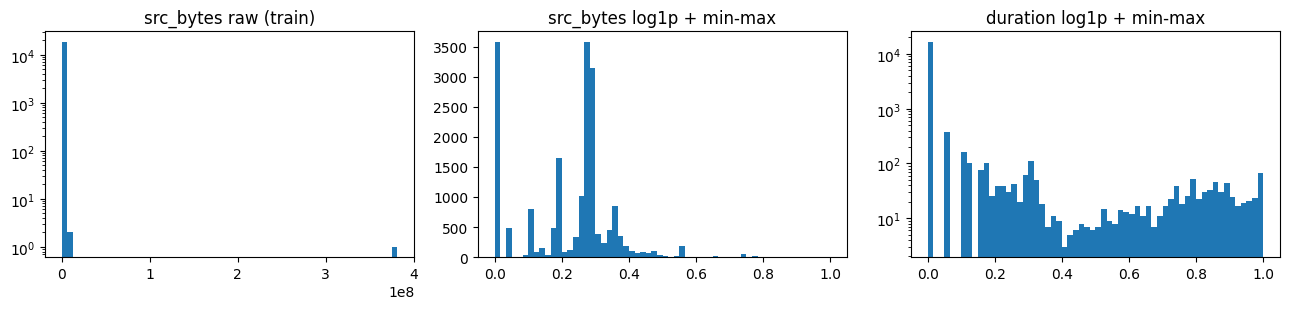

In [20]:
num_idx = [i for i, n in enumerate(FEATURE_NAMES) if not n.startswith('cat__')]
summ = pd.DataFrame({'train mean': X_train[:, num_idx].mean(0), 'test mean': X_test[:, num_idx].mean(0),
                     'test min': X_test[:, num_idx].min(0), 'test max': X_test[:, num_idx].max(0)},
                    index=FEATURE_NAMES[num_idx]).round(3)
print('MinMax: train range is [0, 1] by construction; test values outside [0, 1]:',
      int(((X_test[:, num_idx] < 0) | (X_test[:, num_idx] > 1)).sum()))
display(summ[(summ['test max'] > 1) | (summ['test min'] < 0)])
summ['shift'] = (summ['test mean'] - summ['train mean'])
print('Largest train->test mean shifts (larger dos share in test):')
display(summ['shift'].abs().sort_values(ascending=False).head(6).round(3))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
axes[0].hist(train_raw['src_bytes'], bins=60); axes[0].set_yscale('log'); axes[0].set_title('src_bytes raw (train)')
i = list(FEATURE_NAMES).index('log_num__src_bytes')
axes[1].hist(X_train[:, i], bins=60); axes[1].set_title('src_bytes log1p + min-max')
j = list(FEATURE_NAMES).index('log_num__duration')
axes[2].hist(X_train[:, j], bins=60); axes[2].set_yscale('log'); axes[2].set_title('duration log1p + min-max')
plt.tight_layout(); plt.show()

### Task 1.3 - Domain-expert heatmaps

Rows: attack labels (train). Columns: the 35 numerical features **after** Task 1.2 (38 numerical attributes minus the 3 constant in train) (`log1p` + min-max), so all features share one [0, 1] colour scale; on raw values `src_bytes` (up to 3.8e8) would flatten every other column. Labels are used here only for exploration.

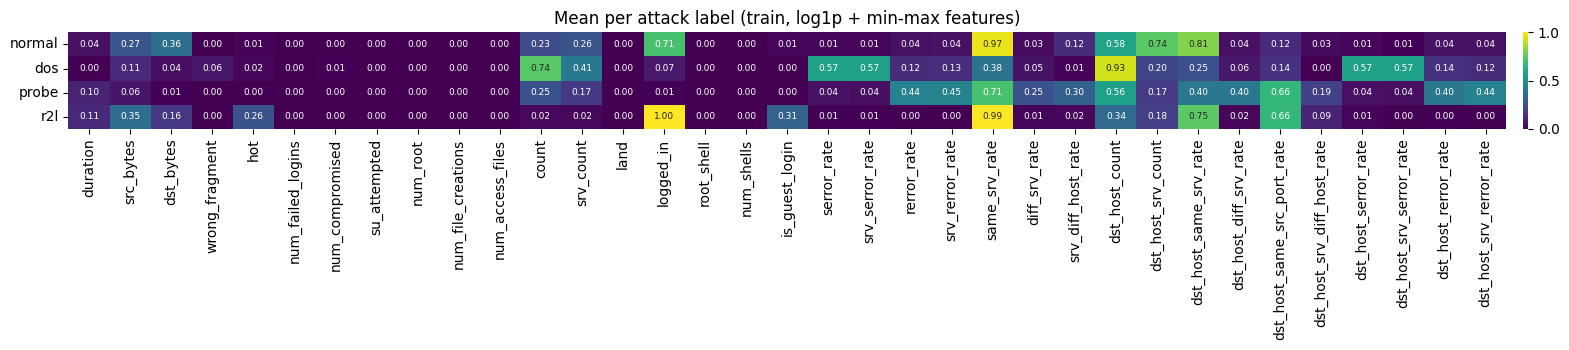

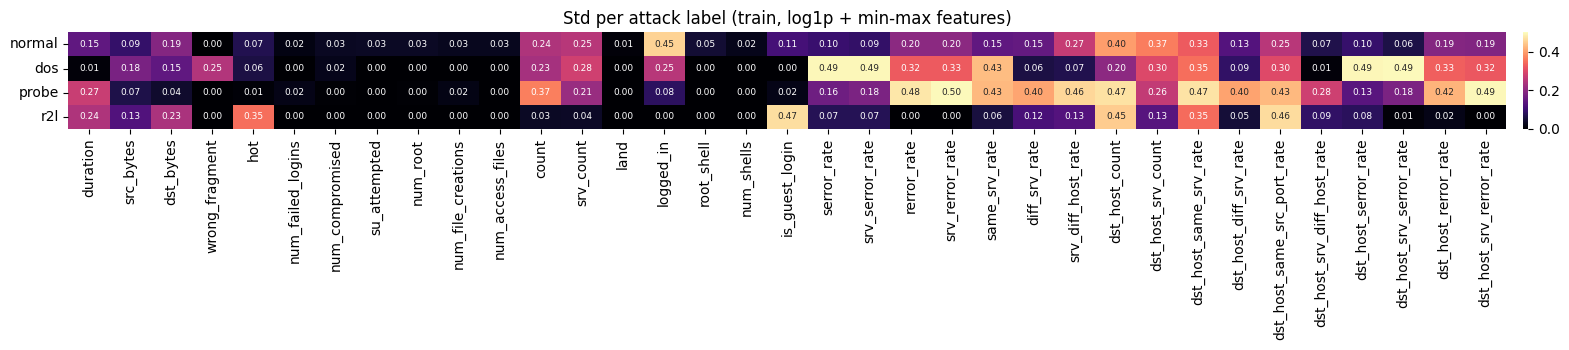

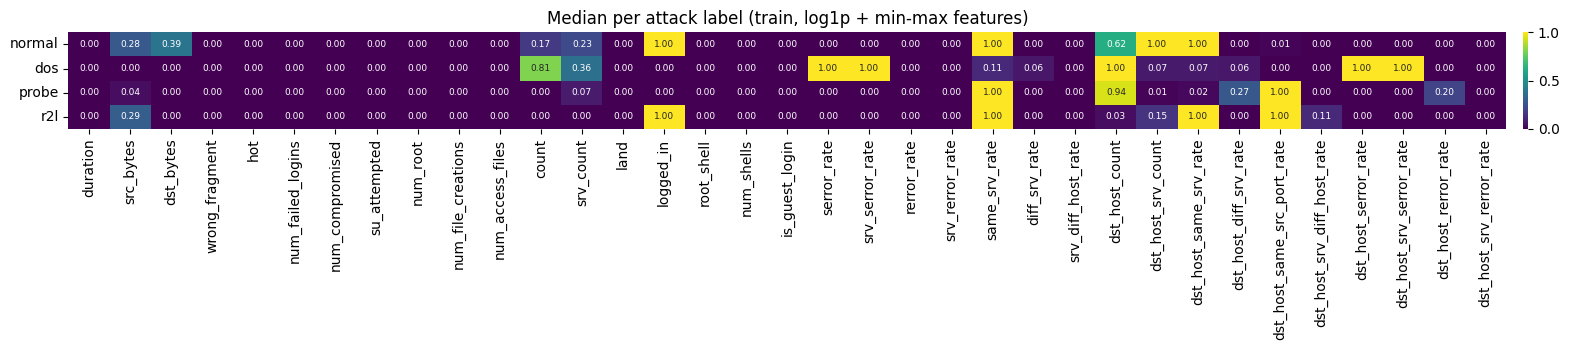

In [21]:
NUM_OUT = [n for n in FEATURE_NAMES if not n.startswith('cat__')]
num_df = pd.DataFrame(X_train[:, [list(FEATURE_NAMES).index(n) for n in NUM_OUT]],
                      columns=[n.split('__', 1)[1] for n in NUM_OUT])
num_df[LABEL] = y_train_lab
ORDER = ['normal', 'dos', 'probe', 'r2l']
stats = {k: num_df.groupby(LABEL).agg(k).reindex(ORDER) for k in ['mean', 'std', 'median']}

for k, cmap in [('mean', 'viridis'), ('std', 'magma'), ('median', 'viridis')]:
    fig, ax = plt.subplots(figsize=(18, 3.6))
    sns.heatmap(stats[k], cmap=cmap, vmin=0, vmax=1 if k != 'std' else 0.5, annot=True, fmt='.2f',
                annot_kws={'size': 6.5}, cbar_kws={'pad': 0.01}, ax=ax)
    ax.set_title(f'{k.capitalize()} per attack label (train, log1p + min-max features)')
    ax.set_xlabel(''); ax.set_ylabel(''); ax.tick_params(axis='y', rotation=0)
    plt.tight_layout(); plt.show()

In [22]:
# Features whose mean differs most from normal, per attack
diff = stats['mean'].sub(stats['mean'].loc['normal'], axis=1).drop('normal')
for lab in diff.index:
    top = diff.loc[lab].abs().sort_values(ascending=False).head(6).index
    print(f'{lab:5s}:', ', '.join(f'{c} ({diff.loc[lab, c]:+.2f})' for c in top))

dos  : logged_in (-0.64), same_srv_rate (-0.59), dst_host_same_srv_rate (-0.56), dst_host_srv_serror_rate (+0.56), serror_rate (+0.56), dst_host_serror_rate (+0.56)
probe: logged_in (-0.70), dst_host_srv_count (-0.57), dst_host_same_src_port_rate (+0.54), dst_host_same_srv_rate (-0.41), srv_rerror_rate (+0.40), dst_host_srv_rerror_rate (+0.40)
r2l  : dst_host_srv_count (-0.56), dst_host_same_src_port_rate (+0.54), is_guest_login (+0.30), logged_in (+0.29), hot (+0.25), dst_host_count (-0.24)


## Task 2 - One-Class SVM: impact of the anomalies

Labels are used only to build the training subsets and to evaluate. All models: RBF kernel, `gamma='scale'`, same preprocessed features (Task 1.2). Prediction `-1` (outside the boundary) = anomaly.

Evaluation on the training file: **FPR** = fraction of normal training connections flagged as anomalous; **macro-F1** = binary macro-F1 on the **full** train.csv (normal + all attacks), so that also the normal-only models are scored on attacks they never saw; per-attack **recall** = fraction of each attack type flagged.

In [23]:
from sklearn.svm import OneClassSVM
from sklearn.metrics import f1_score, confusion_matrix

ATTACKS = ['dos', 'probe', 'r2l']
RESULTS = {}

def evaluate(pred_anom, y_bin, y_lab):
    """pred_anom: 1 = flagged anomalous. Returns binary macro-F1, FPR and per-attack recall."""
    tn, fp, fn, tp = confusion_matrix(y_bin, pred_anom, labels=[0, 1]).ravel()
    out = {'macro_f1': f1_score(y_bin, pred_anom, average='macro'), 'FPR': fp / (fp + tn),
           'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp}
    for a in ATTACKS:
        m = y_lab == a
        if m.any(): out[f'recall_{a}'] = pred_anom[m].mean()
    return out

def run_ocsvm(run_id, X_fit, nu, note=''):
    t0 = time.perf_counter()
    model = OneClassSVM(kernel='rbf', gamma='scale', nu=nu).fit(X_fit)
    fit_s = time.perf_counter() - t0
    pred = (model.predict(X_train) == -1).astype(int)          # scored on the full training file
    res = evaluate(pred, y_train_bin, y_train_lab)
    res.update({'nu': nu, 'n_fit': len(X_fit), 'n_SV': len(model.support_), 'fit_s': fit_s, 'note': note})
    RESULTS[run_id] = res
    print(f'{run_id}: nu={nu:.4f}, n_fit={len(X_fit)}, SV={len(model.support_)} ({len(model.support_)/len(X_fit):.1%}), '
          f'fit {fit_s:.1f}s | FPR={res["FPR"]:.4f}, macro-F1={res["macro_f1"]:.4f}, '
          + ', '.join(f'{a}={res.get(f"recall_{a}", np.nan):.3f}' for a in ATTACKS))
    return model

def results_table(ids):
    cols = ['nu', 'n_fit', 'n_SV', 'FPR', 'macro_f1', 'recall_dos', 'recall_probe', 'recall_r2l', 'FP', 'FN', 'fit_s']
    return pd.DataFrame({k: RESULTS[k] for k in ids}).T[cols]

### Task 2A - Normal traffic only

`nu` is an upper bound on the fraction of training points left outside the boundary (and a lower bound on the fraction of support vectors). With clean normal data every point outside is a false alarm, so `nu` ≈ the training FPR we accept. We choose **`nu = 0.01`**: we tolerate ~1% false alarms (~134 of 13,448 normal connections), enough slack for the rare but legitimate normal patterns seen in Task 1 (rare services, sparse indicators). `nu` cannot be 0: sklearn requires `nu ∈ (0, 1]`, and with `nu → 0` the boundary would have to enclose every training point, including noisy ones.

In [24]:
X_train_normal = X_train[y_train_bin == 0]
print('normal-only training set:', X_train_normal.shape)
ocsvm_run1 = run_ocsvm('run1_normal_nu0.01', X_train_normal, nu=0.01, note='normal only')
ocsvm_run2 = run_ocsvm('run2_normal_nu0.5',  X_train_normal, nu=0.5,  note='normal only, default nu')
display(results_table(['run1_normal_nu0.01', 'run2_normal_nu0.5']).round(4))

normal-only training set: (13448, 106)
run1_normal_nu0.01: nu=0.0100, n_fit=13448, SV=153 (1.1%), fit 0.1s | FPR=0.0104, macro-F1=0.9367, dos=0.910, probe=0.844, r2l=0.017
run2_normal_nu0.5: nu=0.5000, n_fit=13448, SV=6726 (50.0%), fit 5.9s | FPR=0.5000, macro-F1=0.6367, dos=0.974, probe=1.000, r2l=0.994


,nu,n_fit,n_SV,FPR,macro_f1,recall_dos,recall_probe,recall_r2l,FP,FN,fit_s
run1_normal_nu0.01,0.01,13448,153,0.01041,0.936723,0.910058,0.844474,0.016575,140,796,0.132882
run2_normal_nu0.5,0.5,13448,6726,0.5,0.636724,0.97391,0.999563,0.994475,6724,78,5.936365


## Task 3 - Local Outlier Factor

**Knowledge assumed.** LOF is fitted on the **full** training file (normal + all attacks, no labels). The only prior knowledge is the aggregate training contamination (28.6%), used to set the threshold — the same *known-contamination* setting as Task 2. Labels are used only to evaluate.

**Score and threshold.** For each point, LOF = average local reachability density of its `n_neighbors` neighbours / its own density: ≈ 1 means "as dense as its neighbours", > 1 means lower density than its neighbours. With `contamination = 0.286` the threshold is the LOF value above which 28.6% of the training points lie. As a comparison that costs no extra fit, we also apply sklearn's `contamination='auto'` threshold (LOF > 1.5, i.e. no knowledge of the contamination) to the same scores.

**`n_neighbors` sweep (logbook run 8, one diagnostic run).** Four values, log-spaced to include the extremes: **5** (very local density), **20** (sklearn default), **100**, **500** (larger than the whole r2l class, 181 rows, and comparable with groups of repeated DoS connections). Distance: Euclidean on the 106 preprocessed features.

**Selection criterion.** Highest binary macro-F1 on the training file, checked against the threshold-free ROC-AUC of the LOF score (to separate ranking quality from the threshold), and explained through the per-attack recall.

In [ ]:
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import roc_auc_score, average_precision_score

K_VALUES = [5, 20, 100, 500]
CONT_TRAIN = y_train_bin.mean()
LOF_RES, LOF_SCORE = {}, {}

for k in K_VALUES:
    t0 = time.perf_counter()
    lof = LocalOutlierFactor(n_neighbors=k, contamination=CONT_TRAIN)
    pred = (lof.fit_predict(X_train) == -1).astype(int)
    fit_s = time.perf_counter() - t0
    score = -lof.negative_outlier_factor_                     # LOF value: > 1 = lower density than neighbours
    res = evaluate(pred, y_train_bin, y_train_lab)
    res.update({'flagged': pred.mean(), 'LOF_threshold': -lof.offset_,
                'ROC_AUC': roc_auc_score(y_train_bin, score), 'AP': average_precision_score(y_train_bin, score),
                'fit_s': fit_s})
    auto = evaluate((score > 1.5).astype(int), y_train_bin, y_train_lab)  # contamination='auto' threshold
    res.update({'auto_flagged': (score > 1.5).mean(), 'auto_macro_f1': auto['macro_f1'], 'auto_FPR': auto['FPR']})
    LOF_RES[k], LOF_SCORE[k] = res, score
    print(f'k={k:>3}: fit {fit_s:5.1f}s | threshold LOF>{res["LOF_threshold"]:.3f} | macro-F1={res["macro_f1"]:.4f}, '
          f'FPR={res["FPR"]:.4f}, AUC={res["ROC_AUC"]:.4f} | '
          + ', '.join(f'{a}={res[f"recall_{a}"]:.3f}' for a in ATTACKS))

sweep = pd.DataFrame(LOF_RES).T
sweep.index.name = 'n_neighbors'
display(sweep[['flagged', 'LOF_threshold', 'macro_f1', 'FPR', 'recall_dos', 'recall_probe', 'recall_r2l',
               'ROC_AUC', 'AP', 'FP', 'FN', 'fit_s']].astype(float).round(4))
print('Same scores, contamination="auto" threshold (LOF > 1.5):')
display(sweep[['auto_flagged', 'auto_macro_f1', 'auto_FPR']].astype(float).round(4))

k=  5: fit   0.5s | threshold LOF>1.139 | macro-F1=0.5145, FPR=0.2776, AUC=0.4972 | dos=0.292, probe=0.317, r2l=0.414


k= 20: fit   0.6s | threshold LOF>1.138 | macro-F1=0.5294, FPR=0.2690, AUC=0.5127 | dos=0.340, probe=0.310, r2l=0.359


k=100: fit   0.9s | threshold LOF>1.236 | macro-F1=0.5774, FPR=0.2416, AUC=0.5933 | dos=0.533, probe=0.240, r2l=0.166


k=500: fit   1.7s | threshold LOF>1.267 | macro-F1=0.5224, FPR=0.2731, AUC=0.4876 | dos=0.447, probe=0.148, r2l=0.381


,flagged,LOF_threshold,macro_f1,FPR,recall_dos,recall_probe,recall_r2l,ROC_AUC,AP,FP,FN,fit_s
n_neighbors,,,,,,,,,,,,
5,0.2859,1.1393,0.5145,0.2776,0.2918,0.3167,0.4144,0.4972,0.3240,3733.0,3733.0,0.5268
20,0.2859,1.1384,0.5294,0.2690,0.3399,0.3102,0.3591,0.5127,0.3588,3618.0,3618.0,0.6418
100,0.2859,1.2363,0.5774,0.2416,0.5335,0.2403,0.1657,0.5933,0.4475,3249.0,3249.0,0.8641
500,0.2859,1.2673,0.5224,0.2731,0.4473,0.1481,0.3812,0.4876,0.3116,3672.0,3672.0,1.7136


Same scores, contamination="auto" threshold (LOF > 1.5):


,auto_flagged,auto_macro_f1,auto_FPR
n_neighbors,,,
5,0.1057,0.4984,0.0950
20,0.1243,0.5339,0.0996
100,0.1854,0.5829,0.1401
500,0.2226,0.5539,0.1926


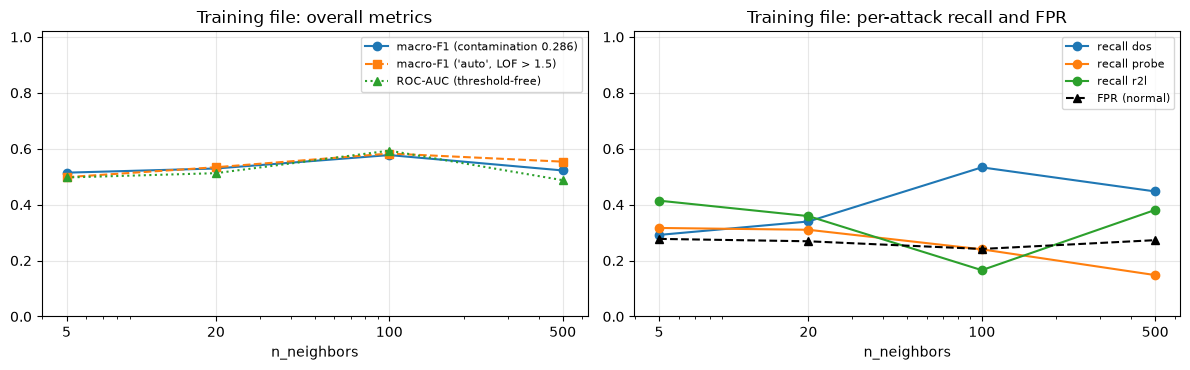

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(K_VALUES, sweep['macro_f1'], 'o-', label='macro-F1 (contamination 0.286)')
axes[0].plot(K_VALUES, sweep['auto_macro_f1'], 's--', label="macro-F1 ('auto', LOF > 1.5)")
axes[0].plot(K_VALUES, sweep['ROC_AUC'], '^:', label='ROC-AUC (threshold-free)')
axes[0].set_title('Training file: overall metrics')
for a in ATTACKS:
    axes[1].plot(K_VALUES, sweep[f'recall_{a}'], 'o-', label=f'recall {a}')
axes[1].plot(K_VALUES, sweep['FPR'], 'k^--', label='FPR (normal)')
axes[1].set_title('Training file: per-attack recall and FPR')
for ax in axes:
    ax.set_xscale('log'); ax.set_xticks(K_VALUES); ax.set_xticklabels(K_VALUES)
    ax.set_xlabel('n_neighbors'); ax.set_ylim(0, 1.02); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Do attacks have lower local density than their neighbours?** Distribution of the LOF value per label for each `n_neighbors` (log scale; red line = known-contamination threshold). A class is detected only if its LOF values lie above the line, i.e. if its points are *sparser than their own neighbours* — not merely far from normal traffic.

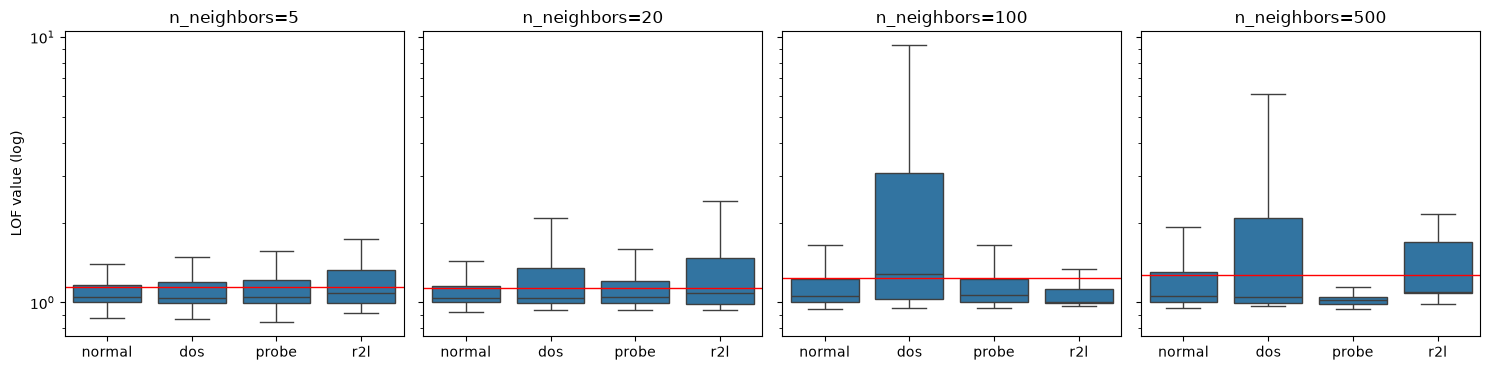

Median LOF value per label:


n_neighbors,5,20,100,500
normal,1.046,1.044,1.059,1.061
dos,1.041,1.042,1.275,1.051
probe,1.047,1.045,1.062,1.020
r2l,1.087,1.088,1.000,1.095


In [ ]:
ORDER = ['normal', 'dos', 'probe', 'r2l']
fig, axes = plt.subplots(1, len(K_VALUES), figsize=(15, 3.8), sharey=True)
for ax, k in zip(axes, K_VALUES):
    df = pd.DataFrame({'label': y_train_lab, 'LOF': LOF_SCORE[k]})
    sns.boxplot(data=df, x='label', y='LOF', order=ORDER, ax=ax, showfliers=False)
    ax.axhline(LOF_RES[k]['LOF_threshold'], color='red', lw=1)
    ax.set_yscale('log'); ax.set_title(f'n_neighbors={k}'); ax.set_xlabel('')
axes[0].set_ylabel('LOF value (log)')
plt.tight_layout(); plt.show()

med = pd.DataFrame({k: pd.Series(LOF_SCORE[k]).groupby(y_train_lab).median() for k in K_VALUES}).loc[ORDER]
med.columns.name = 'n_neighbors'
print('Median LOF value per label:')
display(med.round(3))

**Diagnostics on the run-8 scores (no new detector is fitted).** (1) Which normal connections become false positives? (2) Why is r2l missed at k = 100 but not at k = 5 or k = 500?

In [ ]:
# (1) False positives at k=100: FP rate within each flag / service, and feature differences vs correctly kept normals
k = 100
norm = y_train_lab == 'normal'
fp = norm & (LOF_SCORE[k] > LOF_RES[k]['LOF_threshold'])
tn = norm & ~fp
print(f'k={k}: {fp.sum()} FP out of {norm.sum()} normal connections (FPR {fp.sum()/norm.sum():.3f})')
for col in ['flag', 'service']:
    t = pd.DataFrame({'n normal': train_raw.loc[norm, col].value_counts(),
                      'n FP': train_raw.loc[fp, col].value_counts()}).fillna(0).astype(int)
    t['FP rate'] = (t['n FP'] / t['n normal']).round(3)
    t['share of all FP'] = (t['n FP'] / fp.sum()).round(3)
    display(t.sort_values('n normal', ascending=False).head(10))
svc_n = train_raw['service'].map(train_raw['service'].value_counts())
big = {c: train_raw.loc[norm, c].quantile(0.99) for c in ['src_bytes', 'dst_bytes', 'duration']}
print('rare service (< 100 training rows): FP', f'{(svc_n[fp] < 100).mean():.3f}', '| all normal', f'{(svc_n[norm] < 100).mean():.3f}')
print('src/dst bytes or duration above the normal 99th percentile: FP',
      f'{np.mean(np.any([train_raw.loc[fp, c] > v for c, v in big.items()], axis=0)):.3f}', '| all normal',
      f'{np.mean(np.any([train_raw.loc[norm, c] > v for c, v in big.items()], axis=0)):.3f}')
num = pd.DataFrame(X_train[:, :35], columns=FEATURE_NAMES[:35])
d = pd.DataFrame({'FP mean': num[fp].mean(), 'kept-normal mean': num[tn].mean()})
d['diff'] = d['FP mean'] - d['kept-normal mean']
print('Numerical features with the largest FP vs kept-normal difference:')
display(d.reindex(d['diff'].abs().sort_values(ascending=False).index).head(8).round(3))

k=100: 3249 FP out of 13448 normal connections (FPR 0.242)


,n normal,n FP,FP rate,share of all FP
flag,,,,
SF,12662,2730,0.216,0.840
REJ,515,259,0.503,0.080
S1,86,83,0.965,0.026
S0,80,74,0.925,0.023
RSTO,44,42,0.955,0.013
RSTR,28,28,1.000,0.009
S2,17,17,1.000,0.005
S3,15,15,1.000,0.005
OTH,1,1,1.000,0.000


,n normal,n FP,FP rate,share of all FP
service,,,,
http,7564,1485,0.196,0.457
domain_u,1817,524,0.288,0.161
smtp,1390,382,0.275,0.118
ftp_data,1000,298,0.298,0.092
other,519,153,0.295,0.047
telnet,209,61,0.292,0.019
private,199,1,0.005,0.000
ftp,176,54,0.307,0.017
urp_i,123,3,0.024,0.001


rare service (< 100 training rows): FP 0.059 | all normal 0.015
src/dst bytes or duration above the normal 99th percentile: FP 0.050 | all normal 0.027
Numerical features with the largest FP vs kept-normal difference:


,FP mean,kept-normal mean,diff
num__dst_host_srv_count,0.609,0.786,-0.177
num__logged_in,0.608,0.741,-0.133
num__dst_host_same_srv_rate,0.734,0.834,-0.100
num__dst_host_same_src_port_rate,0.187,0.100,0.088
num__dst_host_rerror_rate,0.102,0.026,0.076
num__srv_rerror_rate,0.099,0.025,0.074
num__dst_host_srv_rerror_rate,0.098,0.025,0.073
num__rerror_rate,0.095,0.025,0.070


In [ ]:
# (2) r2l: duplicates? who are the neighbours of r2l points for each k?
from sklearn.neighbors import NearestNeighbors
r2l = y_train_lab == 'r2l'
print('r2l rows:', r2l.sum(), '| unique preprocessed r2l vectors:', len(np.unique(X_train[r2l], axis=0)))
print('r2l service/flag:', train_raw.loc[r2l, ['service', 'flag']].value_counts().to_dict())
nn = NearestNeighbors(n_neighbors=max(K_VALUES) + 1).fit(X_train)
_, idx = nn.kneighbors(X_train[r2l])                     # column 0 is the point itself
rows = {}
for k in K_VALUES:
    neigh = y_train_lab[idx[:, 1:k + 1]]
    rows[k] = {**{f'neighbours {l}': (neigh == l).mean() for l in ORDER},
               'r2l median LOF': np.median(LOF_SCORE[k][r2l]), 'r2l recall': LOF_RES[k]['recall_r2l']}
display(pd.DataFrame(rows).T.rename_axis('n_neighbors').round(3))

r2l rows: 181 | unique preprocessed r2l vectors: 181
r2l service/flag: {('ftp_data', 'SF'): 122, ('ftp', 'SF'): 57, ('ftp_data', 'S2'): 1, ('other', 'SF'): 1}


,neighbours normal,neighbours dos,neighbours probe,neighbours r2l,r2l median LOF,r2l recall
n_neighbors,,,,,,
5,0.085,0.000,0.000,0.915,1.087,0.414
20,0.116,0.000,0.000,0.884,1.088,0.359
100,0.293,0.000,0.000,0.707,1.000,0.166
500,0.808,0.006,0.001,0.185,1.095,0.381


In [ ]:
K_STAR = int(sweep['macro_f1'].astype(float).idxmax())
print(f'Selected n_neighbors = {K_STAR} (highest training macro-F1; ROC-AUC {LOF_RES[K_STAR]["ROC_AUC"]:.4f})')

Selected n_neighbors = 100 (highest training macro-F1; ROC-AUC 0.5933)


### Task 3 - Test evaluation (logbook run 9)

The selected configuration is refitted on the full training file with `novelty=True`: in sklearn this is required to score **new** points (`fit_predict` only labels the data it was fitted on). The threshold is still the one implied by the training contamination (28.6%), while the test contamination is 63.1%.

n_neighbors=100, fit 0.6s | test macro-F1=0.5691, FPR=0.3518, AUC=0.6053, flagged=0.463 | dos=0.611, probe=0.336


,pred normal,pred anomaly
true normal,1395,757
true anomaly,1731,1943


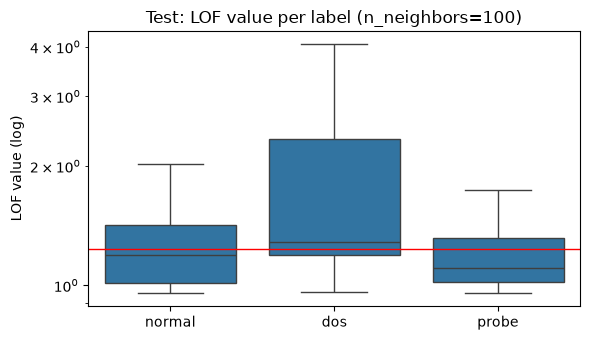

In [ ]:
t0 = time.perf_counter()
lof_final = LocalOutlierFactor(n_neighbors=K_STAR, contamination=CONT_TRAIN, novelty=True).fit(X_train)
fit_s = time.perf_counter() - t0
test_score = -lof_final.score_samples(X_test)
pred_test = (lof_final.predict(X_test) == -1).astype(int)
res_test = evaluate(pred_test, y_test_bin, y_test_lab)
res_test.update({'flagged': pred_test.mean(), 'ROC_AUC': roc_auc_score(y_test_bin, test_score), 'fit_s': fit_s})
print(f'n_neighbors={K_STAR}, fit {fit_s:.1f}s | test macro-F1={res_test["macro_f1"]:.4f}, FPR={res_test["FPR"]:.4f}, '
      f'AUC={res_test["ROC_AUC"]:.4f}, flagged={res_test["flagged"]:.3f} | '
      + ', '.join(f'{a}={res_test[f"recall_{a}"]:.3f}' for a in ATTACKS if f'recall_{a}' in res_test))
display(pd.DataFrame([[res_test['TN'], res_test['FP']], [res_test['FN'], res_test['TP']]],
                     index=['true normal', 'true anomaly'], columns=['pred normal', 'pred anomaly']))

fig, ax = plt.subplots(figsize=(6, 3.5))
sns.boxplot(x=y_test_lab, y=test_score, order=['normal', 'dos', 'probe'], showfliers=False, ax=ax)
ax.axhline(-lof_final.offset_, color='red', lw=1); ax.set_yscale('log')
ax.set_title(f'Test: LOF value per label (n_neighbors={K_STAR})'); ax.set_ylabel('LOF value (log)')
plt.tight_layout(); plt.show()